In [2]:
import pandas as pd

text_columns = [
    "tmc_code", "id", "direction", "traffic_lane_closure_count",
    "week", "road_name", "road_type", "incident_id", "description",
]

number_columns = [
    "speed", "average_speed", "reference_speed",
    "travel_time_minutes", "confidence_score", "cvalue", "order",
    "miles", "distance_to_work_zone", "distance_e_to_wz",
    "sholder_closure_count", "volume", "max_lanes_closed",
    "on_ramp", "off_ramp", "lanes",
]

timestamp_columns = [
    "measurement_tstamp",
    "start_time",
    "end_time",
    "time_start_record",
    "time_end_record",
]

# Read all data as text first. This is robust for mixed text columns and
# prevents pandas from guessing the wrong type.
data = pd.read_csv(
    "export.csv",
    dtype="string",
    na_values=["", "NA"],
    keep_default_na=True,
    low_memory=False,
)

timestamp_format = "%Y %b %d %I:%M:%S %p"
for column in timestamp_columns:
    data[column] = pd.to_datetime(
        data[column],
        format=timestamp_format,
        errors="coerce",
    )

for column in text_columns:
    data[column] = data[column].astype("string")

for column in number_columns:
    cleaned = data[column].str.replace(",", "", regex=False)
    data[column] = pd.to_numeric(cleaned, errors="coerce").astype("Float64")

In [22]:
print(data.shape)
data

(2845040, 30)


,tmc_code,measurement_tstamp,speed,average_speed,reference_speed,travel_time_minutes,confidence_score,cvalue,start_time,end_time,...,week,volume,max_lanes_closed,road_name,road_type,on_ramp,off_ramp,incident_id,description,lanes
0,110+11683,2017-02-10 20:30:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
1,110+11683,2017-02-10 20:45:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
2,110+11683,2017-02-10 21:00:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
3,110+11683,2017-02-10 21:15:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
4,110+11683,2017-02-10 21:30:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2845035,110P04518,2016-01-09 11:30:00,61.34,59.0,57.0,0.38,30.0,92.6,2016-01-09 05:59:14,2016-01-09 10:42:49,...,Saturday,1468.0,<NA>,I695,(Intercontinental Highway) Expressway,0.0,0.0,<NA>,<NA>,5.0
2845036,110P04518,2016-01-09 11:45:00,62.25,59.0,57.0,0.37,30.0,94.47,2016-01-09 05:59:14,2016-01-09 10:42:49,...,Saturday,1468.0,<NA>,I695,(Intercontinental Highway) Expressway,0.0,0.0,<NA>,<NA>,5.0
2845037,110P04518,2016-01-09 12:00:00,63.24,58.0,57.0,0.37,30.0,95.4,2016-01-09 05:59:14,2016-01-09 10:42:49,...,Saturday,1514.0,<NA>,I695,(Intercontinental Highway) Expressway,0.0,0.0,<NA>,<NA>,5.0
2845038,110P04518,2016-01-09 12:15:00,59.87,58.0,57.0,0.39,30.0,100.0,2016-01-09 05:59:14,2016-01-09 10:42:49,...,Saturday,1514.0,<NA>,I695,(Intercontinental Highway) Expressway,0.0,0.0,<NA>,<NA>,5.0


In [16]:
import pandas as pd

accidents = pd.read_csv('accidents.csv')
accidents

,tmc_code,measurement_tstamp,speed,average_speed,reference_speed,travel_time_minutes,confidence_score,cvalue,start_time,end_time,...,week,volume,max_lanes_closed,road_name,road_type,on_ramp,off_ramp,incident_id,description,lanes
0,110P04537,2016-01-20 08:45:00,58.19,45.0,60.0,0.40,30.0,100.00,2016-01-20 11:52:26,2016-01-20 15:20:42,...,Wednesday,1465.0,NaN,I695,(Intercontinental Highway) Expressway,0.0,0.0,bbff9679b58c019f0056fa2ec4235c0a,"Collision, Property Damage",5.0
1,110+04626,2018-03-16 08:30:00,15.83,54.0,60.0,4.32,30.0,100.00,2018-03-16 10:27:02,2018-03-16 15:00:22,...,Friday,1620.0,NaN,I495,(Intercontinental Highway) Expressway,0.0,0.0,6b000874b9b705ab005afa2ec4235c0a,"Collision, Property Damage",5.0
2,110+04626,2018-03-16 08:45:00,32.73,54.0,60.0,2.09,30.0,100.00,2018-03-16 10:27:02,2018-03-16 15:00:22,...,Friday,1620.0,NaN,I495,(Intercontinental Highway) Expressway,0.0,0.0,6b000874b9b705ab005afa2ec4235c0a,"Collision, Property Damage",5.0
3,110-04343,2017-06-10 11:15:00,22.95,68.0,66.0,12.61,30.0,100.00,2017-06-10 11:12:58,2017-06-10 11:14:57,...,Saturday,988.0,4.0,US50,US Highways,0.0,0.0,4d01b13d440c053c0059fa2ec4235c0a,"Collision, Personal Injury",4.0
4,110-04343,2017-06-10 11:30:00,8.83,68.0,66.0,32.77,30.0,96.47,2017-06-10 11:12:58,2017-06-10 11:14:57,...,Saturday,988.0,4.0,US50,US Highways,0.0,0.0,4d01b13d440c053c0059fa2ec4235c0a,"Collision, Personal Injury",4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1629,110N17120,2016-01-07 23:45:00,68.24,66.0,66.0,1.08,30.0,88.87,2016-01-08 09:04:32,2016-01-08 15:04:48,...,Thursday,447.0,NaN,I95,(Intercontinental Highway) Expressway,0.0,0.0,3f0047e3813a008f0056fa2ec4235c0a,"Collision, Personal Injury",5.0
1630,110N04261,2016-01-08 10:15:00,48.12,63.0,64.0,0.97,30.0,100.00,2016-01-08 09:04:32,2016-01-08 15:04:48,...,Friday,1330.0,2.0,I95,(Intercontinental Highway) Expressway,0.0,0.0,b5ff57979cd1008f0056fa2ec4235c0a,"Collision, Property Damage",5.0
1631,110N04261,2016-01-08 10:30:00,24.74,63.0,64.0,1.88,30.0,100.00,2016-01-08 09:04:32,2016-01-08 15:04:48,...,Friday,1330.0,2.0,I95,(Intercontinental Highway) Expressway,0.0,0.0,b5ff57979cd1008f0056fa2ec4235c0a,"Collision, Property Damage",5.0
1632,110N04261,2016-01-08 10:45:00,60.47,63.0,64.0,0.77,30.0,100.00,2016-01-08 09:04:32,2016-01-08 15:04:48,...,Friday,1330.0,2.0,I95,(Intercontinental Highway) Expressway,0.0,0.0,b5ff57979cd1008f0056fa2ec4235c0a,"Collision, Property Damage",5.0


In [17]:
print(accidents.shape)
accidents['description'].unique()

(1634, 30)


<ArrowStringArray>
['Collision, Property Damage', 'Collision, Personal Injury',
        'Collision, Fatality']
Length: 3, dtype: str

In [18]:
accidents['description'].value_counts(normalize=True).mul(100).round(2).astype(str)+'%'

description
Collision, Property Damage    70.81%
Collision, Personal Injury    27.72%
Collision, Fatality            1.47%
Name: proportion, dtype: str

In [19]:
accidents.describe()

,speed,average_speed,reference_speed,travel_time_minutes,confidence_score,cvalue,order,miles,distance_to_work_zone,distance_e_to_wz,sholder_closure_count,traffic_lane_closure_count,volume,max_lanes_closed,on_ramp,off_ramp,lanes
count,1634.000000,1634.000000,1634.000000,1634.000000,1634.000000,1593.000000,1634.000000,1634.000000,1634.000000,1634.000000,1634.000000,1634.000000,1469.000000,738.000000,1634.000000,1634.000000,1634.000000
mean,47.491989,56.241542,58.621787,1.362528,29.558519,89.773139,-2.369645,0.788395,2682.682568,666.132810,0.088127,0.086903,886.341048,2.247967,0.137087,0.369033,4.848225
std,18.609091,9.688798,6.417228,2.499415,2.126489,16.380130,3.175296,0.796881,2490.025286,892.971476,0.283567,0.324221,514.461934,1.376100,0.344044,0.482691,0.451140
min,2.090000,12.000000,27.000000,0.020000,10.000000,9.770000,-16.000000,0.010464,7.099220,1.363414,0.000000,0.000000,22.000000,1.000000,0.000000,0.000000,3.000000
25%,34.640000,54.000000,58.000000,0.422500,30.000000,86.000000,-4.000000,0.426952,488.930507,239.788476,0.000000,0.000000,424.000000,1.000000,0.000000,0.000000,5.000000
50%,55.285000,59.000000,59.000000,0.640000,30.000000,97.730000,-2.000000,0.588342,2015.968447,510.831388,0.000000,0.000000,934.000000,2.000000,0.000000,0.000000,5.000000
75%,61.667500,62.000000,63.000000,1.305000,30.000000,100.000000,0.000000,0.858943,4763.296369,779.267264,0.000000,0.000000,1252.000000,3.000000,0.000000,1.000000,5.000000
max,76.030000,68.000000,67.000000,33.850000,30.000000,100.000000,4.000000,7.875610,12049.758313,9506.783762,1.000000,2.000000,2649.000000,8.000000,1.000000,1.000000,5.000000


In [23]:
correlation = accidents.select_dtypes(include="number").corr()

strong_pairs = {}
for index, column1 in enumerate(correlation.columns):
    for column2 in correlation.columns[index + 1:]:
        value = correlation.loc[column1, column2]
        if abs(value) >= 0.25:
            strong_pairs[(column1, column2)] = value

pd.Series(strong_pairs, name="Correlation").sort_values()

order                  distance_to_work_zone        -0.740307
speed                  travel_time_minutes          -0.493890
distance_to_work_zone  traffic_lane_closure_count   -0.250782
miles                  distance_e_to_wz              0.256295
cvalue                 volume                        0.271666
miles                  distance_to_work_zone         0.298015
on_ramp                off_ramp                      0.314678
speed                  average_speed                 0.379019
travel_time_minutes    miles                         0.565129
sholder_closure_count  traffic_lane_closure_count    0.662642
average_speed          reference_speed               0.729948
Name: Correlation, dtype: float64

In [3]:
outlier_counts = {}
numeric_columns = accidents.select_dtypes(include="number").columns

for column in numeric_columns:
    mean=accidents[column].mean()
    std = accidents[column].std()
    mask = (accidents[column] < mean - 3*std) | (accidents[column] > mean + 3*std)
    outlier_counts[column] = int(mask.sum())

pd.Series(outlier_counts, name="std outlier count").sort_values(ascending=False)

sholder_closure_count         144
reference_speed                70
lanes                          61
confidence_score               51
miles                          47
cvalue                         41
average_speed                  39
travel_time_minutes            37
distance_e_to_wz               26
order                          24
traffic_lane_closure_count     21
volume                          5
distance_to_work_zone           5
max_lanes_closed                5
speed                           0
on_ramp                         0
off_ramp                        0
Name: std outlier count, dtype: int64

In [4]:
import plotly.express as px

var="travel_time_minutes"

mean = accidents[var].div(accidents['miles']).mean()
std = accidents[var].div(accidents['miles']).std()

outliers = accidents[
    (accidents[var].div(accidents['miles']) < mean - 3*std)
    | (accidents[var].div(accidents['miles']) > mean + 3*std)
]

print("Std outliers:", len(outliers))
px.box(accidents, y=var, points="outliers", title="Outliers").show()

Std outliers: 28


In [5]:
px.histogram(
    accidents,
    x="travel_time_minutes",
    nbins=10,
    title="Travel Time Distribution",
).show()

In [6]:
px.histogram(
    accidents[accidents['travel_time_minutes'] <= 2],
    x="travel_time_minutes",
    nbins=10,
    title="Travel Time Distribution",
).show()

In [7]:
px.histogram(
    accidents,
    x="speed",
    nbins=10,
    title="Speed Distribution",
).show()

In [8]:
excluded = {"id", "tmc_code", "incident_id"}

columns = {column for column in data.columns if column not in excluded and column in accidents.columns}

In [9]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

for column in columns:
    av = accidents[column].dropna()
    nv = data[column].dropna()
    if av.empty or nv.empty:
        continue

    fig = make_subplots(rows=1, cols=2, subplot_titles=("Accidents", "Normal Traffic"))

    is_text = pd.api.types.is_string_dtype(av.dtype) or pd.api.types.is_object_dtype(av.dtype)

    if is_text:
        categories = sorted(set(av.astype(str)) | set(nv.astype(str)))
        ac = av.astype(str).value_counts().reindex(categories, fill_value=0)
        nc = nv.astype(str).value_counts().reindex(categories, fill_value=0)
        ap, npv = ac / ac.sum(), nc / nc.sum()
        fig.add_bar(x=categories, y=ap, hovertemplate="%{x}<br>Probability: %{y:.3f}<extra></extra>", row=1, col=1)
        fig.add_bar(x=categories, y=npv, hovertemplate="%{x}<br>Probability: %{y:.3f}<extra></extra>", row=1, col=2)
    else:
        av = pd.to_numeric(av, errors="coerce").dropna()
        nv = pd.to_numeric(nv, errors="coerce").dropna()

        def filtered(values):
            q1, q3 = values.quantile([.25, .75])
            iqr = q3 - q1
            kept = values[(values >= q1 - 1.5 * iqr) & (values <= q3 + 1.5 * iqr)]
            return kept if kept.nunique() > 10 else values

        av, nv = filtered(av), filtered(nv)
        if av.empty or nv.empty:
            continue

        combined = pd.concat([av, nv])
        edges = np.histogram_bin_edges(combined, bins=min(combined.nunique(), 10))
        ac, _ = np.histogram(av, bins=edges)
        nc, _ = np.histogram(nv, bins=edges)
        ap, npv = ac / ac.sum(), nc / nc.sum()
        centers = (edges[:-1] + edges[1:]) / 2
        width = edges[1] - edges[0]
        ranges = list(zip(edges[:-1], edges[1:]))

        fig.add_bar(x=centers, y=ap, width=width, customdata=ranges,
                    hovertemplate="Range: %{customdata[0]}–%{customdata[1]}<br>Probability: %{y:.3f}<extra></extra>",
                    row=1, col=1)
        fig.add_bar(x=centers, y=npv, width=width, customdata=ranges,
                    hovertemplate="Range: %{customdata[0]}–%{customdata[1]}<br>Probability: %{y:.3f}<extra></extra>",
                    row=1, col=2)

    fig.update_layout(title=f"{column}", title_x=.5, showlegend=False,
                      yaxis=dict(range=[0, 1]), yaxis2=dict(range=[0, 1]))
    fig.show()

In [35]:
import pandas as pd
from scipy.stats import chi2_contingency

results = []

for column in columns:
    av = accidents[column].dropna().astype(str)
    nv = data[column].dropna().astype(str)

    if av.empty or nv.empty:
        continue

    categories = sorted(set(av) | set(nv))
    ac = av.value_counts().reindex(categories, fill_value=0)
    nc = nv.value_counts().reindex(categories, fill_value=0)

    table = pd.DataFrame({
        "Accidents": ac,
        "Normal Traffic": nc
    })

    table = table.loc[table.sum(axis=1) > 0]

    if table.shape[0] < 2:
        continue

    _, p_value, dof, _ = chi2_contingency(table.to_numpy())

    results.append({
        "column": column,
        "degrees_of_freedom": dof,
        "p_value": p_value,
    })

results = pd.DataFrame(results).sort_values("p_value")
results["adjusted_p_value"] = (
    results["p_value"] * len(results)
).clip(upper=1)

results["p_value"] = results["p_value"].round(4)
results["adjusted_p_value"] = results["adjusted_p_value"].round(4)

display(results)

,column,degrees_of_freedom,p_value,adjusted_p_value
0,miles,4499,0.000000e+00,0.000000e+00
2,start_time,5952,0.000000e+00,0.000000e+00
3,volume,2292,0.000000e+00,0.000000e+00
4,distance_e_to_wz,3153,0.000000e+00,0.000000e+00
6,road_name,167,0.000000e+00,0.000000e+00
5,road_type,2,0.000000e+00,0.000000e+00
11,time_start_record,5952,0.000000e+00,0.000000e+00
8,time_end_record,5889,0.000000e+00,0.000000e+00
14,measurement_tstamp,96160,0.000000e+00,0.000000e+00
13,lanes,2,0.000000e+00,0.000000e+00


In [36]:
results["p_value"] = results["p_value"].round(4)
results["adjusted_p_value"] = results["adjusted_p_value"].round(4)

display(results)

,column,degrees_of_freedom,p_value,adjusted_p_value
0,miles,4499,0.0,0.0
2,start_time,5952,0.0,0.0
3,volume,2292,0.0,0.0
4,distance_e_to_wz,3153,0.0,0.0
6,road_name,167,0.0,0.0
5,road_type,2,0.0,0.0
11,time_start_record,5952,0.0,0.0
8,time_end_record,5889,0.0,0.0
14,measurement_tstamp,96160,0.0,0.0
13,lanes,2,0.0,0.0


In [37]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

results = []

for column in columns:
    av = accidents[column].dropna()
    nv = data[column].dropna()

    if av.empty or nv.empty:
        continue

    if pd.api.types.is_numeric_dtype(av.dtype):
        av = pd.to_numeric(av, errors="coerce").dropna()
        nv = pd.to_numeric(nv, errors="coerce").dropna()
        combined = pd.concat([av, nv])

        bin_count = min(combined.nunique(), 10)
        if bin_count < 1:
            continue

        edges = np.histogram_bin_edges(combined, bins=max(bin_count, 1))
        ac, _ = np.histogram(av, bins=edges)
        nc, _ = np.histogram(nv, bins=edges)
        table = np.vstack([ac, nc])
    else:
        categories = sorted(set(av.astype(str)) | set(nv.astype(str)))
        ac = av.astype(str).value_counts().reindex(categories, fill_value=0)
        nc = nv.astype(str).value_counts().reindex(categories, fill_value=0)
        table = np.vstack([ac.to_numpy(), nc.to_numpy()])

    table = table[:, table.sum(axis=0) > 0]

    if table.shape[1] < 2:
        continue

    _, p_value, dof, _ = chi2_contingency(table)

    results.append({
        "column": column,
        "degrees_of_freedom": dof,
        "p_value": p_value
    })

results = pd.DataFrame(results).sort_values("p_value")
results["adjusted_p_value"] = (
    results["p_value"] * len(results)
).clip(upper=1)
results["significant"] = results["adjusted_p_value"] < 0.05

display(results)

,column,degrees_of_freedom,p_value,adjusted_p_value,significant
2,start_time,5952,0.000000e+00,0.000000e+00,True
5,road_type,2,0.000000e+00,0.000000e+00,True
6,road_name,167,0.000000e+00,0.000000e+00,True
8,time_end_record,5889,0.000000e+00,0.000000e+00,True
13,lanes,2,0.000000e+00,0.000000e+00,True
14,measurement_tstamp,96160,0.000000e+00,0.000000e+00,True
11,time_start_record,5952,0.000000e+00,0.000000e+00,True
17,travel_time_minutes,9,0.000000e+00,0.000000e+00,True
18,end_time,5889,0.000000e+00,0.000000e+00,True
3,volume,9,3.297551e-291,8.903387e-290,True


In [39]:
correlation

,speed,average_speed,reference_speed,travel_time_minutes,confidence_score,cvalue,order,miles,distance_to_work_zone,distance_e_to_wz,sholder_closure_count,traffic_lane_closure_count,volume,max_lanes_closed,on_ramp,off_ramp,lanes
speed,1.000000,0.379019,0.240920,-0.493890,-0.095792,0.074279,-0.122348,0.006301,0.121670,-0.001192,-0.000015,0.023795,-0.107960,-0.236795,-0.058005,0.001267,0.020144
average_speed,0.379019,1.000000,0.729948,0.083273,-0.062409,-0.029017,-0.013473,0.181220,0.051743,0.082989,0.082745,0.054334,-0.119761,0.206557,-0.078827,-0.083654,0.079810
reference_speed,0.240920,0.729948,1.000000,0.164208,0.018752,0.079638,-0.040855,0.197763,0.114461,0.116215,0.035827,-0.018923,0.161261,0.229167,-0.052777,-0.130072,0.134782
travel_time_minutes,-0.493890,0.083273,0.164208,1.000000,0.035823,0.009043,0.112696,0.565129,0.138196,0.106115,0.101034,0.005230,0.002548,0.180862,0.020868,-0.080855,-0.081008
confidence_score,-0.095792,-0.062409,0.018752,0.035823,1.000000,0.068466,0.107820,-0.030430,-0.059067,0.028528,-0.025212,-0.015374,0.133129,-0.138247,0.050968,0.057401,0.008064
cvalue,0.074279,-0.029017,0.079638,0.009043,0.068466,1.000000,0.034794,0.040333,0.008652,0.024944,0.048461,0.024222,0.271666,-0.129370,0.021026,0.029859,0.099468
order,-0.122348,-0.013473,-0.040855,0.112696,0.107820,0.034794,1.000000,0.117098,-0.740307,-0.003544,0.232071,0.200152,-0.003762,-0.012693,-0.126796,-0.059573,-0.010974
miles,0.006301,0.181220,0.197763,0.565129,-0.030430,0.040333,0.117098,1.000000,0.298015,0.256295,0.035025,-0.066506,-0.036082,0.032125,0.005162,-0.066086,-0.116462
distance_to_work_zone,0.121670,0.051743,0.114461,0.138196,-0.059067,0.008652,-0.740307,0.298015,1.000000,-0.040954,-0.235702,-0.250782,0.051113,0.037306,0.129475,0.044872,-0.008302
distance_e_to_wz,-0.001192,0.082989,0.116215,0.106115,0.028528,0.024944,-0.003544,0.256295,-0.040954,1.000000,-0.025443,-0.021569,-0.018937,-0.045289,-0.086479,-0.144428,-0.128769


In [42]:
display(data.columns)
data

Index(['tmc_code', 'measurement_tstamp', 'speed', 'average_speed',
       'reference_speed', 'travel_time_minutes', 'confidence_score', 'cvalue',
       'start_time', 'end_time', 'time_start_record', 'time_end_record', 'id',
       'order', 'miles', 'direction', 'distance_to_work_zone',
       'distance_e_to_wz', 'sholder_closure_count',
       'traffic_lane_closure_count', 'week', 'volume', 'max_lanes_closed',
       'road_name', 'road_type', 'on_ramp', 'off_ramp', 'incident_id',
       'description', 'lanes'],
      dtype='str')

,tmc_code,measurement_tstamp,speed,average_speed,reference_speed,travel_time_minutes,confidence_score,cvalue,start_time,end_time,...,week,volume,max_lanes_closed,road_name,road_type,on_ramp,off_ramp,incident_id,description,lanes
0,110+11683,2017-02-10 20:30:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
1,110+11683,2017-02-10 20:45:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
2,110+11683,2017-02-10 21:00:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
3,110+11683,2017-02-10 21:15:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
4,110+11683,2017-02-10 21:30:00,42.0,42.0,41.0,2.98,20.0,<NA>,2017-02-11 08:17:28,2017-02-11 12:00:02,...,Friday,<NA>,<NA>,MD31,State Road,0.0,0.0,<NA>,<NA>,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2845035,110P04518,2016-01-09 11:30:00,61.34,59.0,57.0,0.38,30.0,92.6,2016-01-09 05:59:14,2016-01-09 10:42:49,...,Saturday,1468.0,<NA>,I695,(Intercontinental Highway) Expressway,0.0,0.0,<NA>,<NA>,5.0
2845036,110P04518,2016-01-09 11:45:00,62.25,59.0,57.0,0.37,30.0,94.47,2016-01-09 05:59:14,2016-01-09 10:42:49,...,Saturday,1468.0,<NA>,I695,(Intercontinental Highway) Expressway,0.0,0.0,<NA>,<NA>,5.0
2845037,110P04518,2016-01-09 12:00:00,63.24,58.0,57.0,0.37,30.0,95.4,2016-01-09 05:59:14,2016-01-09 10:42:49,...,Saturday,1514.0,<NA>,I695,(Intercontinental Highway) Expressway,0.0,0.0,<NA>,<NA>,5.0
2845038,110P04518,2016-01-09 12:15:00,59.87,58.0,57.0,0.39,30.0,100.0,2016-01-09 05:59:14,2016-01-09 10:42:49,...,Saturday,1514.0,<NA>,I695,(Intercontinental Highway) Expressway,0.0,0.0,<NA>,<NA>,5.0


In [30]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

excluded={'tmc_code', 'measurement_tstamp', 'average_speed', 'confidence_score', 'cvalue', 'start_time', 'end_time', 'time_start_record', 'time_end_record', 'id', 'order', 'volume', 'road_name', 'incident_id', 'description', 'distance_e_to_wz', 'max_lanes_closed','road_name'}

numeric_columns=['lanes','speed','reference_speed','travel_time_minutes','miles','distance_to_work_zone','sholder_closure_count','traffic_lane_closure_count']
categorical_columns=['on_ramp','off_ramp','road_type','week','direction']


numeric_pipeline = Pipeline([
    ("polynomial", PolynomialFeatures(degree=4,include_bias=False)),
    ("scaler", StandardScaler())
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", OneHotEncoder(handle_unknown='ignore'), categorical_columns)
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegressionCV(cv=5, max_iter=10000))
])

X = data.drop(columns=excluded)
y = data['incident_id'].notna().astype("int64")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

accident_train = X_train[y_train==1]
normal_train = X_train[y_train==0]
n_accidents = len(accident_train)
n_normal = min(2*n_accidents, len(normal_train))

normal_train=normal_train.sample(n=n_normal, random_state=42)

X_train_balanced = pd.concat([accident_train, normal_train]).sample(frac=1, random_state=42)
y_train_balanced = y_train.loc[X_train_balanced.index]

model.fit(X_train_balanced, y_train_balanced)

print("Train accuracy:", model.score(X_train_balanced, y_train_balanced))
print("Test accuracy:", model.score(X_test, y_test))

C:\Users\Josiah\miniconda3\envs\NotebookData\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
C:\Users\Josiah\miniconda3\envs\NotebookData\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
C:\Users\Josiah\miniconda3\envs\NotebookData\Lib\site-packages\sklearn\linear_model\_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.1

Train accuracy: 0.8416220351951033
Test accuracy: 0.8874514945308326


In [13]:
classifier = model.named_steps["classifier"]
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

weights = pd.Series(
    classifier.coef_[0],
    index=feature_names,
).sort_values(key=abs, ascending=False)

weights

numeric__speed^3 reference_speed                           -80.491928
numeric__speed^2 reference_speed travel_time_minutes        69.539221
numeric__speed travel_time_minutes distance_to_work_zone    69.195105
numeric__speed reference_speed distance_to_work_zone        65.359139
numeric__lanes reference_speed distance_to_work_zone^2     -64.513758
                                                              ...    
categorical__off_ramp_1.0                                    0.057045
numeric__reference_speed^2 sholder_closure_count            -0.025541
categorical__week_Friday                                    -0.022745
categorical__week_Thursday                                   0.019580
categorical__direction_Outer Loop                            0.003412
Length: 514, dtype: float64

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision for y=1:", precision_score(y_test, predictions))
print("Recall for y=1:", recall_score(y_test, predictions))
print("F1 for y=1:", f1_score(y_test, predictions))
print("Confusion matrix:\n", confusion_matrix(y_test, predictions))

Accuracy: 0.8874514945308326
Precision for y=1: 0.003568534563360967
Recall for y=1: 0.7003058103975535
F1 for y=1: 0.007100885285043179
Confusion matrix:
 [[504738  63943]
 [    98    229]]


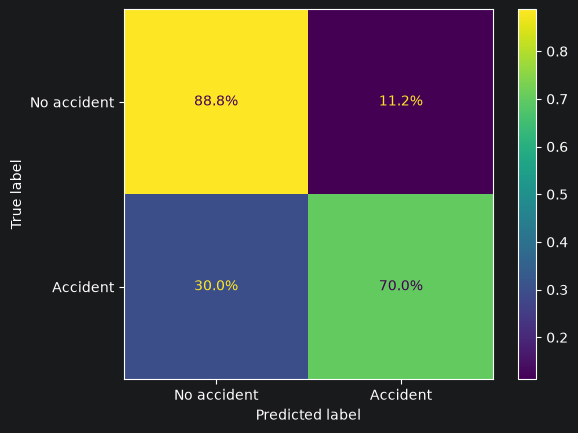

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix(
        y_test,
        predictions,
        normalize="true",
    ),
    display_labels=["No accident", "Accident"],
).plot(values_format=".1%")

In [33]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

excluded={'tmc_code', 'measurement_tstamp', 'average_speed', 'confidence_score', 'cvalue', 'start_time', 'end_time', 'time_start_record', 'time_end_record', 'id', 'order', 'volume', 'road_name', 'incident_id', 'description', 'distance_e_to_wz', 'max_lanes_closed','road_name'}

numeric_columns=['lanes','speed','reference_speed','travel_time_minutes','miles','distance_to_work_zone','sholder_closure_count','traffic_lane_closure_count']
categorical_columns=['on_ramp','off_ramp','road_type','week','direction']


preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown='ignore'), categorical_columns),
    ("numeric", "passthrough", numeric_columns),
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(max_depth=8,class_weight="balanced",random_state=42))
])

X = data.drop(columns=excluded)
y = data['incident_id'].notna().astype("int64")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

accident_train = X_train[y_train==1]
normal_train = X_train[y_train==0]
n_accidents = len(accident_train)
n_normal = min(2*n_accidents, len(normal_train))

normal_train=normal_train.sample(n=n_normal, random_state=42)

X_train_balanced = pd.concat([accident_train, normal_train]).sample(frac=1, random_state=42)
y_train_balanced = y_train.loc[X_train_balanced.index]

model.fit(X_train_balanced, y_train_balanced)

print("Train accuracy:", model.score(X_train_balanced, y_train_balanced))
print("Test accuracy:", model.score(X_test, y_test))

Train accuracy: 0.8775822494261668
Test accuracy: 0.8017795883361921


In [87]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import f1_score, classification_report, confusion_matrix

parameter_grid = {
    "tree__max_depth": [3, 5, 8, None],
    "tree__min_samples_leaf": [1, 5, 20],
    "tree__criterion": ["gini", "entropy"],
    "tree__class_weight": [None, "balanced"],
}

search = GridSearchCV(
    model,
    parameter_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

nested_scores = cross_val_score(
    search,
    X_train_balanced,
    y_train_balanced,
    cv=outer_cv,
    scoring="f1",
    n_jobs=-1,
)

print("Nested validation F1:", nested_scores)
print("Mean nested F1:", nested_scores.mean())
print("Nested F1 standard deviation:", nested_scores.std())

search.fit(X_train_balanced, y_train_balanced)

print("Best parameters:", search.best_params_)
print("Best validation F1:", search.best_score_)

predictions = search.predict(X_test)
probabilities = search.predict_proba(X_test)[:, 1]

print("Test F1:", f1_score(y_test, predictions))
print(classification_report(
    y_test,
    predictions,
    target_names=["No accident", "Accident"],
))

print("Test confusion matrix:")
print(confusion_matrix(y_test, predictions))

Nested validation F1: [0.82661996 0.76697248 0.82709447 0.85765766 0.85245902]
Mean nested F1: 0.8261607180484697
Nested F1 standard deviation: 0.03221176300545281
Best parameters: {'tree__class_weight': 'balanced', 'tree__criterion': 'entropy', 'tree__max_depth': None, 'tree__min_samples_leaf': 1}
Best validation F1: 0.8210586393175723
Test F1: 0.00874056416368693
              precision    recall  f1-score   support

 No accident       1.00      0.89      0.94    568681
    Accident       0.00      0.87      0.01       327

    accuracy                           0.89    569008
   macro avg       0.50      0.88      0.47    569008
weighted avg       1.00      0.89      0.94    569008

Test confusion matrix:
[[503852  64829]
 [    41    286]]


In [35]:
model.set_params(tree__max_depth=None, tree__min_samples_leaf=1, tree__criterion='entropy', tree__class_weight='balanced')

model.fit(X_train_balanced, y_train_balanced)

predictions=model.predict(X_test)
probabilities=model.predict_proba(X_test)

print("Train accuracy:", model.score(X_train_balanced, y_train_balanced))
print("Test accuracy:", model.score(X_test, y_test))

Train accuracy: 0.9997449630196379
Test accuracy: 0.8859945730112757


In [36]:
print("Confusion matrix:\n", confusion_matrix(y_test, predictions))

Confusion matrix:
 [[503852  64829]
 [    41    286]]


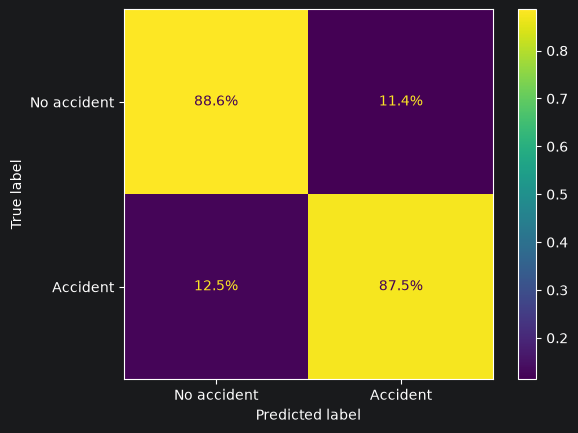

In [89]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix(
        y_test,
        predictions,
        normalize="true",
    ),
    display_labels=["No accident", "Accident"],
).plot(values_format=".1%")

In [91]:
tree = model.named_steps["tree"]

feature_names = model.named_steps["preprocessor"].get_feature_names_out()

importances = pd.Series(
    tree.feature_importances_,
    index=feature_names,
).sort_values(ascending=False)

display(importances.to_frame("importance"))

,importance
numeric__lanes,0.189241
numeric__miles,0.159211
numeric__distance_to_work_zone,0.130492
numeric__speed,0.127512
numeric__reference_speed,0.125819
numeric__travel_time_minutes,0.107313
categorical__week_Thursday,0.020120
categorical__direction_North,0.012880
categorical__direction_South,0.011906
categorical__direction_Outer Loop,0.010184


In [92]:
importances[importances >= 0.01].index

Index(['numeric__lanes', 'numeric__miles', 'numeric__distance_to_work_zone',
       'numeric__speed', 'numeric__reference_speed',
       'numeric__travel_time_minutes', 'categorical__week_Thursday',
       'categorical__direction_North', 'categorical__direction_South',
       'categorical__direction_Outer Loop'],
      dtype='str')

In [10]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

columns={'lanes','miles','speed','reference_speed','distance_to_work_zone','travel_time_minutes','week','direction'}

for column in columns:
    av = accidents[column].dropna()
    nv = data[column].dropna()
    if av.empty or nv.empty:
        continue

    fig = make_subplots(rows=1, cols=2, subplot_titles=("Accidents", "Normal Traffic"))

    is_text = pd.api.types.is_string_dtype(av.dtype) or pd.api.types.is_object_dtype(av.dtype)

    if is_text:
        categories = sorted(set(av.astype(str)) | set(nv.astype(str)))
        ac = av.astype(str).value_counts().reindex(categories, fill_value=0)
        nc = nv.astype(str).value_counts().reindex(categories, fill_value=0)
        ap, npv = ac / ac.sum(), nc / nc.sum()
        fig.add_bar(x=categories, y=ap, hovertemplate="%{x}<br>Probability: %{y:.3f}<extra></extra>", row=1, col=1)
        fig.add_bar(x=categories, y=npv, hovertemplate="%{x}<br>Probability: %{y:.3f}<extra></extra>", row=1, col=2)
    else:
        av = pd.to_numeric(av, errors="coerce").dropna()
        nv = pd.to_numeric(nv, errors="coerce").dropna()

        def filtered(values):
            q1, q3 = values.quantile([.25, .75])
            iqr = q3 - q1
            kept = values[(values >= q1 - 1.5 * iqr) & (values <= q3 + 1.5 * iqr)]
            return kept if kept.nunique() > 10 else values

        av, nv = filtered(av), filtered(nv)
        if av.empty or nv.empty:
            continue

        combined = pd.concat([av, nv])
        edges = np.histogram_bin_edges(combined, bins=min(combined.nunique(), 10))
        ac, _ = np.histogram(av, bins=edges)
        nc, _ = np.histogram(nv, bins=edges)
        ap, npv = ac / ac.sum(), nc / nc.sum()
        centers = (edges[:-1] + edges[1:]) / 2
        width = edges[1] - edges[0]
        ranges = list(zip(edges[:-1], edges[1:]))

        fig.add_bar(x=centers, y=ap, width=width, customdata=ranges,
                    hovertemplate="Range: %{customdata[0]}–%{customdata[1]}<br>Probability: %{y:.3f}<extra></extra>",
                    row=1, col=1)
        fig.add_bar(x=centers, y=npv, width=width, customdata=ranges,
                    hovertemplate="Range: %{customdata[0]}–%{customdata[1]}<br>Probability: %{y:.3f}<extra></extra>",
                    row=1, col=2)

    fig.update_layout(title=f"{column}", title_x=.5, showlegend=False,
                      yaxis=dict(range=[0, 1]), yaxis2=dict(range=[0, 1]))
    fig.show()

In [28]:
accident_speeds = accidents.copy()

accident_speeds["speed"] = pd.to_numeric(
    accident_speeds["speed"], errors="coerce"
)
accident_speeds["reference_speed"] = pd.to_numeric(
    accident_speeds["reference_speed"], errors="coerce"
)
accident_speeds = accident_speeds.dropna(
    subset=["speed", "reference_speed"]
).copy()

accident_speeds["speed_difference"] = (
    accident_speeds["speed"]
    - accident_speeds["reference_speed"]
)

# Bin by reference speed
bins = np.linspace(
    accident_speeds["reference_speed"].min(),
    accident_speeds["reference_speed"].max(),
    10
)

counts = np.zeros(len(bins) - 1)
hover_text = []

for i in range(len(bins) - 1):
    lower = bins[i]
    upper = bins[i + 1]

    in_bin = accident_speeds[
        (accident_speeds["reference_speed"] >= lower)
        & (accident_speeds["reference_speed"] < upper)
    ]

    counts[i] = len(in_bin)

    if len(in_bin):
        reference_min = in_bin["reference_speed"].min()
        reference_max = in_bin["reference_speed"].max()

        speed_min = in_bin["speed"].min()
        speed_max = in_bin["speed"].max()

        average_difference = in_bin["speed_difference"].mean()

        hover_text.append(
            f"Reference speed range: "
            f"{reference_min:.1f}–{reference_max:.1f}<br>"
            f"Actual speed range: {speed_min:.1f}–{speed_max:.1f}<br>"
            f"Average difference: {average_difference:.2f}<br>"
            f"Accidents: {len(in_bin)}"
        )
    else:
        hover_text.append(
            f"Reference speed range: {lower:.1f}–{upper:.1f}<br>"
            "No accident observations"
        )

fig = go.Figure(
    go.Bar(
        x=(bins[:-1] + bins[1:]) / 2,
        y=counts,
        width=np.diff(bins),
        customdata=hover_text,
        hovertemplate="%{customdata}<extra></extra>",
    )
)

fig.update_layout(
    title="Reference Speed Distribution for Accidents",
    xaxis_title="Reference Speed",
    yaxis_title="Number of Accident Observations",
)
fig.show()